# Paso 4 · Cerrar el modelo de riesgo

**Qué predecimos:** la probabilidad de que un muestreo registre **blanqueamiento apreciable (> 10 % de los corales)**.

**Punto de partida (paso 3):** una regresión logística con el estrés térmico (`tsa_dhw`). Ahora probamos a añadir, **de una en una**, variables con sentido biológico, y solo nos quedamos con las que mejoran de forma consistente **y** cuyo efecto va en la dirección que dice la ciencia.

¿Por qué logística y no XGBoost? En el paso 3, el modelo simple compitió con los complejos. Además, la logística es **interpretable** (cada variable tiene un coeficiente con signo) y **se puede calcular en el navegador** con 4 números: la app no necesitaría backend para predecir.

In [1]:
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, average_precision_score

df = pd.read_csv("../data/coral_reefcheck.csv")
df = df[df["year"] >= 2003].copy()          # antes de 2003 casi no hay muestreos de Reef Check
df["y"] = (df["percent_bleaching"] > 10).astype(int)

# Transformaciones con sentido:
df["log_dhw"] = np.log1p(df["tsa_dhw"])               # el efecto del calor se satura: de 0 a 4 importa más que de 16 a 20
df["lat_dev"] = (df["abs_latitude"] - 17.5) ** 2       # distancia a la franja 15–20°, donde más se blanquea (Sully et al. 2019)
print(len(df), "muestreos ·", df["y"].mean().round(3), "con blanqueamiento apreciable")

11107 muestreos · 0.058 con blanqueamiento apreciable


## 1. Una trampa al evaluar: los empates
El **74 % de los muestreos tiene `tsa_dhw = 0`**. El modelo base les da a todos la misma probabilidad. Cualquier variable que añadas "desempata" esos casos y puede subir el AUC **aunque no aporte nada real**.

Por eso usamos dos cosas más robustas:
- **Validación por años:** entrenamos con todos los años menos uno, probamos en ese año, y repetimos con cada año. Así medimos si el modelo generaliza a años que no ha visto.
- **Log-loss skill:** cuánto mejoran las *probabilidades* respecto a decir siempre la media. 0 % = no aporta nada; cuanto más alto, mejor.

In [2]:
def leave_one_year_out(cols):
    ll, ll_prior, pr = [], [], []
    for year in sorted(df["year"].unique()):
        tr, te = df[df["year"] != year], df[df["year"] == year]
        if te["y"].sum() < 5:
            continue
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(tr[cols], tr["y"])
        p = m.predict_proba(te[cols])[:, 1]
        ll.append(log_loss(te["y"], p, labels=[0, 1]))
        ll_prior.append(log_loss(te["y"], np.full(len(te), tr["y"].mean()), labels=[0, 1]))
        pr.append(average_precision_score(te["y"], p))
    full = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(df[cols], df["y"])
    return {"skill %": 100 * (1 - np.mean(ll) / np.mean(ll_prior)), "PR-AUC": np.mean(pr),
            "coeficientes": dict(zip(cols, full[-1].coef_[0].round(2)))}

candidates = {
    "base (solo calor)": ["log_dhw"],
    "+ variabilidad térmica": ["log_dhw", "ssta_sd"],
    "+ latitud": ["log_dhw", "lat_dev"],
    "+ frecuencia de estrés": ["log_dhw", "tsa_frequency"],
    "+ profundidad": ["log_dhw", "depth_m"],
    "+ año": ["log_dhw", "year"],
    "+ variabilidad + latitud": ["log_dhw", "ssta_sd", "lat_dev"],
}
table = pd.DataFrame({name: leave_one_year_out(cols) for name, cols in candidates.items()}).T
table

,skill %,PR-AUC,coeficientes
base (solo calor),3.712246,0.131201,{'log_dhw': 0.44}
+ variabilidad térmica,4.462319,0.140377,"{'log_dhw': 0.54, 'ssta_sd': -0.36}"
+ latitud,4.002407,0.144341,"{'log_dhw': 0.44, 'lat_dev': -0.29}"
+ frecuencia de estrés,3.598061,0.133421,"{'log_dhw': 0.45, 'tsa_frequency': -0.01}"
+ profundidad,3.585126,0.132444,"{'log_dhw': 0.44, 'depth_m': 0.03}"
+ año,3.312439,0.131201,"{'log_dhw': 0.44, 'year': 0.09}"
+ variabilidad + latitud,4.753244,0.146721,"{'log_dhw': 0.54, 'ssta_sd': -0.32, 'lat_dev':..."


## 2. Leer los coeficientes con ojos de biólogo
Los coeficientes están estandarizados: se comparan entre sí y el signo dice la dirección.

| Variable | Signo esperado | ¿Por qué? |
|---|---|---|
| `log_dhw` | **+** | Más calor acumulado, más blanqueamiento. |
| `ssta_sd` | **−** | Los corales de aguas con temperatura muy variable están "entrenados" y toleran mejor los picos. |
| `lat_dev` | **−** | Cuanto más lejos de la franja 15–20°, menos blanqueamiento (patrón global de Sully et al. 2019). |
| `tsa_frequency` | ¿? | Estrés repetido: puede debilitar o aclimatar. En nuestros datos el signo cambia según el modelo → **señal inestable, fuera**. |
| `depth_m` | − esperado | En nuestros datos sale **+** y empeora la validación. Probablemente refleja *dónde* muestrea Reef Check, no biología → **fuera**. |
| `year` | ¿? | Apenas mejora y obligaría a la app a elegir un año → **fuera** por ahora. |

✅ **Modelo final:** `log_dhw` + `ssta_sd` + `lat_dev`. Las tres mejoran la validación **y** tienen el signo que espera la ciencia.

In [3]:
FEATURES = ["log_dhw", "ssta_sd", "lat_dev"]
final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(df[FEATURES], df["y"])
scaler, logit = final[0], final[-1]
pd.Series(logit.coef_[0], index=FEATURES).round(3)

log_dhw    0.537
ssta_sd   -0.321
lat_dev   -0.268
dtype: float64

## 3. Curvas de riesgo con incertidumbre
Repetimos el ajuste 200 veces sobre remuestreos de los datos (*bootstrap*). La banda muestra cuánto podría variar la curva si hubiéramos tenido otros muestreos. Comparamos aguas **estables** y **variables** a 17,5° de latitud.

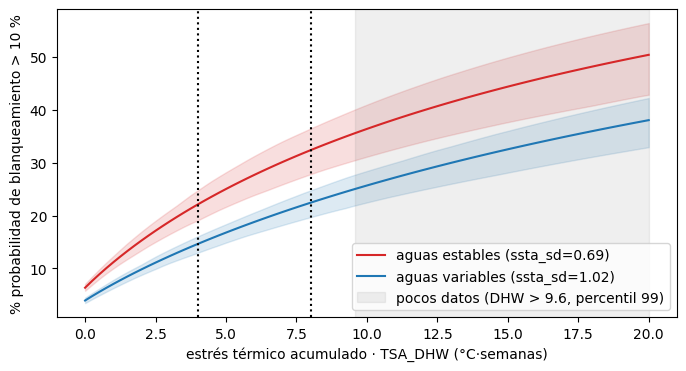

In [4]:
rng = np.random.default_rng(42)
dhw = np.linspace(0, 20, 81)
sd_stable, sd_variable = df["ssta_sd"].quantile([0.1, 0.9])

def curve(model, sd, lat=17.5):
    X = pd.DataFrame({"log_dhw": np.log1p(dhw), "ssta_sd": sd, "lat_dev": (lat - 17.5) ** 2})
    return model.predict_proba(X)[:, 1] * 100

fig, ax = plt.subplots(figsize=(8, 4))
for sd, label, color in [(sd_stable, "aguas estables", "tab:red"), (sd_variable, "aguas variables", "tab:blue")]:
    boots = []
    for _ in range(200):
        s = df.sample(len(df), replace=True, random_state=int(rng.integers(1e9)))
        boots.append(curve(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(s[FEATURES], s["y"]), sd))
    lo, hi = np.percentile(boots, [5, 95], axis=0)
    ax.fill_between(dhw, lo, hi, color=color, alpha=0.15)
    ax.plot(dhw, curve(final, sd), color=color, label=f"{label} (ssta_sd={sd:.2f})")
p99 = df["tsa_dhw"].quantile(0.99)
ax.axvspan(p99, 20, color="grey", alpha=0.12, label=f"pocos datos (DHW > {p99:.1f}, percentil 99)")
for v in (4, 8):
    ax.axvline(v, ls=":", color="k")
ax.set(xlabel="estrés térmico acumulado · TSA_DHW (°C·semanas)", ylabel="% probabilidad de blanqueamiento > 10 %")
ax.legend(); plt.show()

## 4. Exportar el modelo para la app
Una logística se calcula con una fórmula sencilla, así que la exportamos como JSON. La app puede calcular el riesgo **en el navegador**, sin servidor:

```
z = intercepto + Σ coef_i · (x_i − media_i) / desviación_i
riesgo = 1 / (1 + e^(−z))
```

También exportamos, por ecorregión, los valores típicos de `ssta_sd` y latitud y su DHW habitual. Así la app solo tiene que mover el calor.

In [5]:
model_json = {
    "name": "reef_pulse_risk_v1",
    "target": "P(percent_bleaching > 10%) in a Reef Check survey",
    "data": "Reef Check 2003–2019, one row per survey (dev-notebooks/02)",
    "features": FEATURES,
    "transforms": {"log_dhw": "ln(1 + tsa_dhw)", "lat_dev": "(abs(latitude) - 17.5)^2"},
    "mean": scaler.mean_.round(6).tolist(),
    "scale": scaler.scale_.round(6).tolist(),
    "coef": logit.coef_[0].round(6).tolist(),
    "intercept": round(float(logit.intercept_[0]), 6),
    "dhw_p95": round(float(df["tsa_dhw"].quantile(0.95)), 2),
    "dhw_p99": round(float(df["tsa_dhw"].quantile(0.99)), 2),
    "baseline_rate": round(float(df["y"].mean()), 4),
}
reefs = (df.groupby("ecoregion").agg(
            n=("y", "size"), lat=("latitude", "mean"), lon=("longitude", "mean"),
            ssta_sd=("ssta_sd", "median"), dhw_typical=("tsa_dhw", "median"),
            dhw_p90=("tsa_dhw", lambda s: s.quantile(0.9)), observed_rate=("y", "mean"),
            ocean=("ocean", lambda s: s.mode()[0]))
         .query("n >= 20").round(4).reset_index())

with open("../models/risk_model_v1.json", "w") as f:
    json.dump(model_json, f, indent=2)
reefs.to_json("../data/reefs_reefcheck.json", orient="records", indent=1)
print(json.dumps(model_json, indent=2)); print(len(reefs), "ecorregiones exportadas")

{
  "name": "reef_pulse_risk_v1",
  "target": "P(percent_bleaching > 10%) in a Reef Check survey",
  "data": "Reef Check 2003\u20132019, one row per survey (dev-notebooks/02)",
  "features": [
    "log_dhw",
    "ssta_sd",
    "lat_dev"
  ],
  "transforms": {
    "log_dhw": "ln(1 + tsa_dhw)",
    "lat_dev": "(abs(latitude) - 17.5)^2"
  },
  "mean": [
    0.315042,
    0.878898,
    72.190332
  ],
  "scale": [
    0.603901,
    0.210556,
    72.553258
  ],
  "coef": [
    0.536863,
    -0.321469,
    -0.268313
  ],
  "intercept": -2.964796,
  "dhw_p95": 4.23,
  "dhw_p99": 9.59,
  "baseline_rate": 0.0583
}
50 ecorregiones exportadas


In [6]:
# Comprobación: la fórmula "a mano" (la que usará la app) coincide con sklearn
row = df[FEATURES].iloc[0].values
z = model_json["intercept"] + np.sum(np.array(model_json["coef"]) * (row - np.array(model_json["mean"])) / np.array(model_json["scale"]))
print("a mano:", 1 / (1 + np.exp(-z)), "· sklearn:", final.predict_proba(df[FEATURES].iloc[[0]])[0, 1])

a mano: 0.041408381109087324 · sklearn: 0.0414084070783481


## 5. Qué contar en la app (honestamente)
- El riesgo **sube claramente con el calor acumulado**, y es **menor en aguas de temperatura variable** y **lejos de la franja 15–20°**.
- La mejora sobre "adivinar la media" es **modesta** (unos puntos de log-loss skill): el blanqueamiento de un muestreo concreto tiene mucho azar (fecha del muestreo, especies, equipo).
- Solo el 5 % de los muestreos de Reef Check supera DHW ≈ 4 y solo el 1 % supera DHW ≈ 10. Por encima de ahí la curva es **extrapolación**: la banda de incertidumbre se abre. En la app, la zona rayada del dial debería empezar en DHW ≈ 10.

✍️ **Siguiente paso (5):** conectar este modelo a la app: el dial de calor mueve `tsa_dhw`, y el coral y la frase muestran el riesgo.